In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


**Install Libraries**

In [ ]:
!pip install -q kagglehub timm

**Section 3:** **Import Libraries**

In [ ]:
import os
import random
import numpy as np

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from torchvision import datasets
from torchvision import transforms

import timm

import matplotlib.pyplot as plt

import kagglehub

**Section 4
Download Dataset**

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

100%|██████████| 157M/157M [00:01<00:00, 142MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2


**Section 5
Explore Dataset**

In [ ]:
import os

print("Dataset Path:", path)
print()

for item in os.listdir(path):
    print(item)

Dataset Path: /root/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2

Testing
Training


In [ ]:
train_dir = os.path.join(path, "Training")
test_dir = os.path.join(path, "Testing")

print("Training:", train_dir)
print("Testing :", test_dir)

print("\nTraining Classes:")
print(os.listdir(train_dir))

print("\nTesting Classes:")
print(os.listdir(test_dir))

Training: /root/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Training
Testing : /root/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Testing

Training Classes:
['notumor', 'pituitary', 'meningioma', 'glioma']

Testing Classes:
['notumor', 'pituitary', 'meningioma', 'glioma']


In [ ]:
for cls in sorted(os.listdir(train_dir)):
    folder = os.path.join(train_dir, cls)
    print(f"{cls:12s} : {len(os.listdir(folder))} images")

glioma       : 1400 images
meningioma   : 1400 images
notumor      : 1400 images
pituitary    : 1400 images


In [ ]:
print("\nTesting Set\n")

for cls in sorted(os.listdir(test_dir)):
    folder = os.path.join(test_dir, cls)
    print(f"{cls:12s} : {len(os.listdir(folder))} images")


Testing Set

glioma       : 400 images
meningioma   : 400 images
notumor      : 400 images
pituitary    : 400 images


In [ ]:
print(sorted(os.listdir(train_dir)))

['glioma', 'meningioma', 'notumor', 'pituitary']


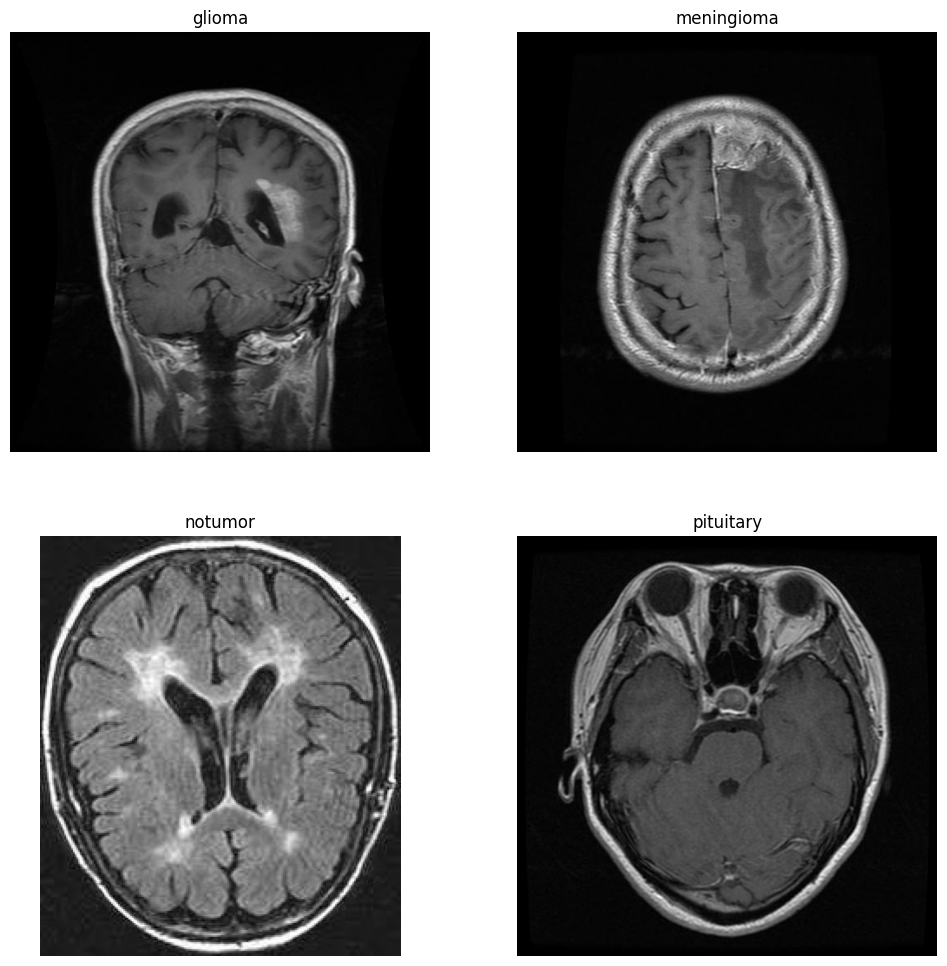

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

classes = sorted(os.listdir(train_dir))

plt.figure(figsize=(12, 12))

for i, cls in enumerate(classes):

    folder = os.path.join(train_dir, cls)

    img_name = random.choice(os.listdir(folder))

    img_path = os.path.join(folder, img_name)

    img = Image.open(img_path)

    plt.subplot(2, 2, i + 1)

    plt.imshow(img, cmap="gray")

    plt.title(cls)

    plt.axis("off")

plt.show()

In [ ]:
from collections import Counter

sizes = Counter()

for cls in classes:
    folder = os.path.join(train_dir, cls)

    for img_name in os.listdir(folder):

        img = Image.open(os.path.join(folder, img_name))

        sizes[img.size] += 1

print("Number of unique image sizes:", len(sizes))

print("\nMost common image sizes:\n")

for size, count in sizes.most_common(10):
    print(size, ":", count)

Number of unique image sizes: 381

Most common image sizes:

(512, 512) : 4012
(225, 225) : 253
(630, 630) : 69
(201, 251) : 40
(236, 236) : 39
(442, 442) : 38
(150, 198) : 33
(232, 217) : 32
(228, 221) : 32
(428, 417) : 31


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/NeuroVision_AI"

folders = [
    PROJECT_DIR,
    f"{PROJECT_DIR}/models",
    f"{PROJECT_DIR}/checkpoints",
    f"{PROJECT_DIR}/outputs",
    f"{PROJECT_DIR}/plots",
    f"{PROJECT_DIR}/reports",
    f"{PROJECT_DIR}/logs",
    f"{PROJECT_DIR}/exports",
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


# Phase 2 — Data Preprocessing

**Image Transformations**

In [ ]:
from torchvision import transforms

In [ ]:
train_transform = transforms.Compose([

    transforms.Grayscale(num_output_channels=3),

    transforms.Resize((224,224)),

    transforms.RandomRotation(10),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05,0.05),
        scale=(0.95,1.05)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std =[0.229,0.224,0.225]
    )
])

In [ ]:
test_transform = transforms.Compose([

    transforms.Grayscale(num_output_channels=3),

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std =[0.229,0.224,0.225]
    )
])

# Phase 3 — Create the Dataset Objects

In [ ]:
from torchvision.datasets import ImageFolder

train_dataset = ImageFolder(
    root=train_dir,
    transform=train_transform
)

test_dataset = ImageFolder(
    root=test_dir,
    transform=test_transform
)

In [ ]:
print("Classes:", train_dataset.classes)
print("Class to Index:", train_dataset.class_to_idx)

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class to Index: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [ ]:
print("Training Images :", len(train_dataset))
print("Testing Images  :", len(test_dataset))

Training Images : 5600
Testing Images  : 1600


# Phase 4 — Create DataLoaders

**Section 6
Create DataLoaders**

In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
images, labels = next(iter(train_loader))

print("Image Batch Shape :", images.shape)
print("Label Shape       :", labels.shape)

Image Batch Shape : torch.Size([32, 3, 224, 224])
Label Shape       : torch.Size([32])


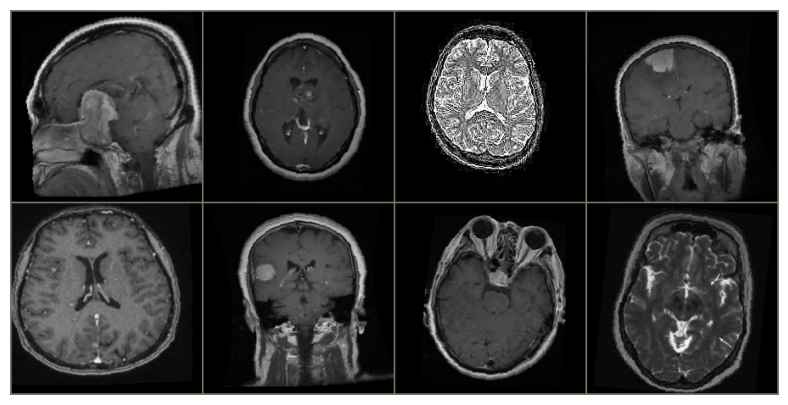

In [ ]:
import matplotlib.pyplot as plt
import torchvision

images, labels = next(iter(train_loader))

grid = torchvision.utils.make_grid(images[:8], nrow=4)

grid = grid.permute(1, 2, 0)

mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

grid = grid.numpy()
grid = std * grid + mean
grid = grid.clip(0, 1)

plt.figure(figsize=(10, 5))
plt.imshow(grid)
plt.axis("off")
plt.show()

**Section 7
Build EfficientNet Model**

### ***Step 1 — Import EfficientNet***

In [ ]:
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

### ***Step 2 — Load Pretrained Weights***

In [ ]:
weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(weights=weights)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 141MB/s]


In [ ]:
print(model)

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [ ]:
total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

Total Parameters     : 5,288,548
Trainable Parameters : 5,288,548


### Step 3: Freeze the *Backbone*

In [ ]:
for param in model.parameters():
    param.requires_grad = False

In [ ]:
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)


In [ ]:
import torch.nn as nn

model.classifier = nn.Sequential(
    nn.Dropout(p=0.2),
    nn.Linear(
        in_features=1280,
        out_features=4
    )
)

In [ ]:
for param in model.classifier.parameters():
    param.requires_grad = True

In [ ]:
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable Parameters: {trainable_params:,}")

Trainable Parameters: 5,124


In [ ]:
model = model.to(device)

In [ ]:
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)


In [ ]:
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

In [ ]:
import torch.optim as optim

optimizer = optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

### Learning Rate Scheduler
Instead of using a fixed learning rate, we'll gradually reduce it during training.

In [ ]:
scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=5,
    gamma=0.1
)

### Hyperparameters


In [ ]:
NUM_EPOCHS = 10
LEARNING_RATE = 0.001
BATCH_SIZE = 32

BEST_MODEL_PATH = (
    f"{PROJECT_DIR}/models/best_model.pth"
)

### Verify Everything

In [ ]:
print("Loss Function :", criterion)
print("Optimizer     :", optimizer)
print("Scheduler     :", scheduler)
print("Epochs        :", NUM_EPOCHS)

Loss Function : CrossEntropyLoss()
Optimizer     : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 0.001
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Scheduler     : <torch.optim.lr_scheduler.StepLR object at 0x7d587fbcdc70>
Epochs        : 10


**Section 8
Training Loop**

the complete flow:
One Epoch

│
├── Batch 1:

│      │

│      ├── Forward Pass

│      ├── Compute Loss

│      ├── Backward Pass

│      ├── Update Weights

│      └── Calculate Accuracy

│

├── Batch 2..

│
├── Batch 3..

│
└── ...

This repeats until every training image has been seen once.

In [ ]:
import time
import copy

best_accuracy = 0.0

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

In [ ]:
for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")
    print("-" * 40)

    model.train()

    running_loss = 0.0
    running_correct = 0
    total = 0

    start_time = time.time()

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        running_correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)

    epoch_acc = 100 * running_correct / total

    train_losses.append(epoch_loss)

    train_accuracies.append(epoch_acc)

    scheduler.step()

    elapsed = time.time() - start_time

    print(f"Loss     : {epoch_loss:.4f}")
    print(f"Accuracy : {epoch_acc:.2f}%")
    print(f"Time     : {elapsed:.1f} sec")


Epoch 1/10
----------------------------------------
Loss     : 0.6243
Accuracy : 79.61%
Time     : 37.7 sec

Epoch 2/10
----------------------------------------
Loss     : 0.4109
Accuracy : 85.95%
Time     : 36.1 sec

Epoch 3/10
----------------------------------------
Loss     : 0.3766
Accuracy : 86.77%
Time     : 37.0 sec

Epoch 4/10
----------------------------------------
Loss     : 0.3464
Accuracy : 88.02%
Time     : 34.9 sec

Epoch 5/10
----------------------------------------
Loss     : 0.3341
Accuracy : 88.46%
Time     : 34.6 sec

Epoch 6/10
----------------------------------------
Loss     : 0.3166
Accuracy : 88.79%
Time     : 36.8 sec

Epoch 7/10
----------------------------------------
Loss     : 0.3091
Accuracy : 89.02%
Time     : 34.5 sec

Epoch 8/10
----------------------------------------
Loss     : 0.3066
Accuracy : 89.54%
Time     : 34.8 sec

Epoch 9/10
----------------------------------------
Loss     : 0.3143
Accuracy : 89.07%
Time     : 35.2 sec

Epoch 10/10
------

In [ ]:
model.eval()

running_loss = 0.0
running_correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        running_correct += (predicted == labels).sum().item()

val_loss = running_loss / len(test_loader)

val_acc = 100 * running_correct / total

val_losses.append(val_loss)

val_accuracies.append(val_acc)

print(f"Validation Loss     : {val_loss:.4f}")
print(f"Validation Accuracy : {val_acc:.2f}%")

Validation Loss     : 0.5300
Validation Accuracy : 83.31%


In [ ]:
if val_acc > best_accuracy:

    best_accuracy = val_acc

    torch.save(
        model.state_dict(),
        BEST_MODEL_PATH
    )

    print("✅ Best model saved!")

✅ Best model saved!


In [ ]:
print("\nTraining Complete!")

print(f"Best Validation Accuracy : {best_accuracy:.2f}%")


Training Complete!
Best Validation Accuracy : 83.31%


# **Fine**-**Tuning**

In [ ]:
print(model.features)

Sequential(
  (0): Conv2dNormActivation(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): SiLU(inplace=True)
  )
  (1): Sequential(
    (0): MBConv(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): SiLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (activation): SiLU(inplace=True)
          (scale_activation): Sigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), 

In [ ]:
model.load_state_dict(torch.load(BEST_MODEL_PATH))

<All keys matched successfully>

In [ ]:
for param in model.parameters():
    param.requires_grad = False

In [ ]:
# Unfreeze last MBConv block
for param in model.features[6].parameters():
    param.requires_grad = True

# Unfreeze final MBConv block
for param in model.features[7].parameters():
    param.requires_grad = True

# Unfreeze final 1x1 convolution
for param in model.features[8].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

In [ ]:
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable Parameters : {trainable_params:,}")

Trainable Parameters : 3,160,864


### New **Optimizer**

In [ ]:
import torch.optim as optim

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-5,
    weight_decay=1e-4
)

Notice two changes:

Learning rate = 1e-5 (100× smaller)

Added weight_decay=1e-4 to reduce overfitting during fine-tuning.

## **New Scheduler**

In [ ]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=2
)

Unlike StepLR, this scheduler reduces the learning rate only when the validation accuracy stops improving, making it more suitable for fine-tuning.

In [ ]:
#Fine-tuning Epochs
NUM_EPOCHS = 10


In [ ]:
FINE_TUNED_MODEL_PATH = (
        f"{PROJECT_DIR}/models/best_model_finetuned.pth"
    )

for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")
    print("-" * 40)

    model.train()

    running_loss = 0.0
    running_correct = 0
    total = 0

    start_time = time.time()

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        running_correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)

    epoch_acc = 100 * running_correct / total

    train_losses.append(epoch_loss)

    train_accuracies.append(epoch_acc)

    #scheduler.step()

    elapsed = time.time() - start_time

    print(f"Loss     : {epoch_loss:.4f}")
    print(f"Accuracy : {epoch_acc:.2f}%")
    print(f"Time     : {elapsed:.1f} sec")
    model.eval()

    running_loss = 0.0
    running_correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            running_correct += (predicted == labels).sum().item()

    val_loss = running_loss / len(test_loader)

    val_acc = 100 * running_correct / total

    val_losses.append(val_loss)

    val_accuracies.append(val_acc)

    print(f"Validation Loss     : {val_loss:.4f}")
    print(f"Validation Accuracy : {val_acc:.2f}%")

    scheduler.step(val_acc)
    print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.7f}")

    if val_acc > best_accuracy:

        best_accuracy = val_acc

        torch.save(
            model.state_dict(),
            FINE_TUNED_MODEL_PATH
        )

        print(f"✅ New Best Model Saved! ({best_accuracy:.2f}%)")


Epoch 1/10
----------------------------------------
Loss     : 0.2059
Accuracy : 92.34%
Time     : 37.6 sec
Validation Loss     : 0.4096
Validation Accuracy : 88.19%
Learning Rate: 0.0000100

Epoch 2/10
----------------------------------------
Loss     : 0.1869
Accuracy : 93.55%
Time     : 37.9 sec
Validation Loss     : 0.4095
Validation Accuracy : 88.69%
Learning Rate: 0.0000100
✅ New Best Model Saved! (88.69%)

Epoch 3/10
----------------------------------------
Loss     : 0.1731
Accuracy : 93.77%
Time     : 38.6 sec
Validation Loss     : 0.3961
Validation Accuracy : 89.00%
Learning Rate: 0.0000100
✅ New Best Model Saved! (89.00%)

Epoch 4/10
----------------------------------------
Loss     : 0.1773
Accuracy : 93.34%
Time     : 38.0 sec
Validation Loss     : 0.4037
Validation Accuracy : 89.06%
Learning Rate: 0.0000100
✅ New Best Model Saved! (89.06%)

Epoch 5/10
----------------------------------------
Loss     : 0.1613
Accuracy : 94.41%
Time     : 38.2 sec
Validation Loss     : 0.

In [ ]:
import os

print(os.path.exists(FINE_TUNED_MODEL_PATH))

True


In [ ]:
print(FINE_TUNED_MODEL_PATH)

/content/drive/MyDrive/NeuroVision_AI/models/best_model_finetuned.pth


In [ ]:
size = os.path.getsize(FINE_TUNED_MODEL_PATH)

print(f"{size/1024/1024:.2f} MB")

15.60 MB


In [ ]:
import os

for root, dirs, files in os.walk(PROJECT_DIR):
    print(root)

    for file in files:
        print("   ", file)

/content/drive/MyDrive/NeuroVision_AI
/content/drive/MyDrive/NeuroVision_AI/models
    best_model.pth
    best_model_finetuned.pth
/content/drive/MyDrive/NeuroVision_AI/checkpoints
/content/drive/MyDrive/NeuroVision_AI/outputs
/content/drive/MyDrive/NeuroVision_AI/plots
/content/drive/MyDrive/NeuroVision_AI/reports
/content/drive/MyDrive/NeuroVision_AI/logs
/content/drive/MyDrive/NeuroVision_AI/exports


**Section 9
Evaluation**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import torch
import torch.nn as nn
import torchvision

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

cuda


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/NeuroVision_AI"

MODEL_PATH = (
    f"{PROJECT_DIR}/models/best_model_finetuned.pth"
)

print(MODEL_PATH)

/content/drive/MyDrive/NeuroVision_AI/models/best_model_finetuned.pth


In [ ]:
model = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

model.classifier = nn.Sequential(
    nn.Dropout(0.2),
    nn.Linear(1280,4)
)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 196MB/s]


In [ ]:
model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device
    )
)

<All keys matched successfully>

In [ ]:
model = model.to(device)

model.eval()

print("Model Loaded Successfully!")

Model Loaded Successfully!


In [ ]:
print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)


In [ ]:
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


In [ ]:
import os

print("Dataset Path:", path)
print()

for item in os.listdir(path):
    print(item)

Dataset Path: /kaggle/input/brain-tumor-mri-dataset

Training
Testing


In [ ]:
from torchvision import transforms
from torchvision.datasets import ImageFolder

test_transform = transforms.Compose([

    transforms.Grayscale(num_output_channels=3),

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std =[0.229,0.224,0.225]
    )
])

TEST_DIR = "/kaggle/input/brain-tumor-mri-dataset/Testing"

test_dataset = ImageFolder(
    TEST_DIR,
    transform=test_transform
)

In [ ]:
from torch.utils.data import DataLoader

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [ ]:
y_true = []
y_pred = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.numpy())

        y_pred.extend(predictions.cpu().numpy())

In [ ]:
print(len(y_true))
print(len(y_pred))

1600
1600


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

print(cm)

[[296  54  42   8]
 [  3 378   9  10]
 [  0   0 400   0]
 [  0   4   0 396]]


<Figure size 800x800 with 0 Axes>

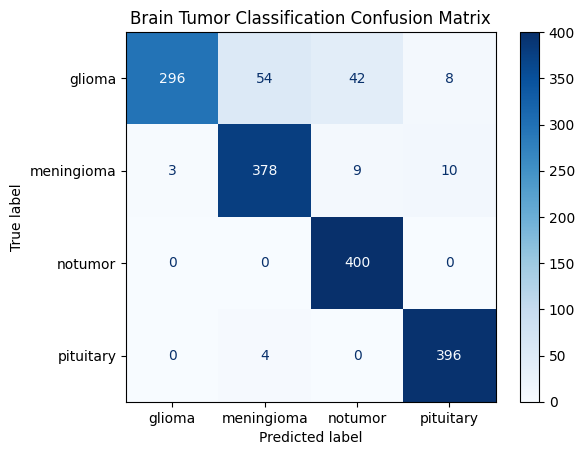

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = test_dataset.classes

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

plt.figure(figsize=(8,8))

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Brain Tumor Classification Confusion Matrix")

plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=test_dataset.classes,
        digits=4
    )
)

              precision    recall  f1-score   support

      glioma     0.9900    0.7400    0.8469       400
  meningioma     0.8670    0.9450    0.9043       400
     notumor     0.8869    1.0000    0.9401       400
   pituitary     0.9565    0.9900    0.9730       400

    accuracy                         0.9187      1600
   macro avg     0.9251    0.9187    0.9161      1600
weighted avg     0.9251    0.9187    0.9161      1600



In [ ]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 86.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

import cv2
import numpy as np

In [ ]:
wrong_image = None
wrong_label = None
wrong_prediction = None

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        preds = outputs.argmax(1)

        for i in range(len(labels)):

            if preds[i] != labels[i]:

                wrong_image = images[i]

                wrong_label = labels[i].item()

                wrong_prediction = preds[i].item()

                break

        if wrong_image is not None:
            break

print("True Class :", test_dataset.classes[wrong_label])
print("Predicted  :", test_dataset.classes[wrong_prediction])

True Class : glioma
Predicted  : pituitary


In [ ]:
target_layers = [model.features[8]]

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam import HiResCAM

cam = HiResCAM(
    model=model,
    target_layers=target_layers
)

input_tensor = wrong_image.unsqueeze(0)

targets = [ClassifierOutputTarget(wrong_prediction)]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)

grayscale_cam = grayscale_cam[0]

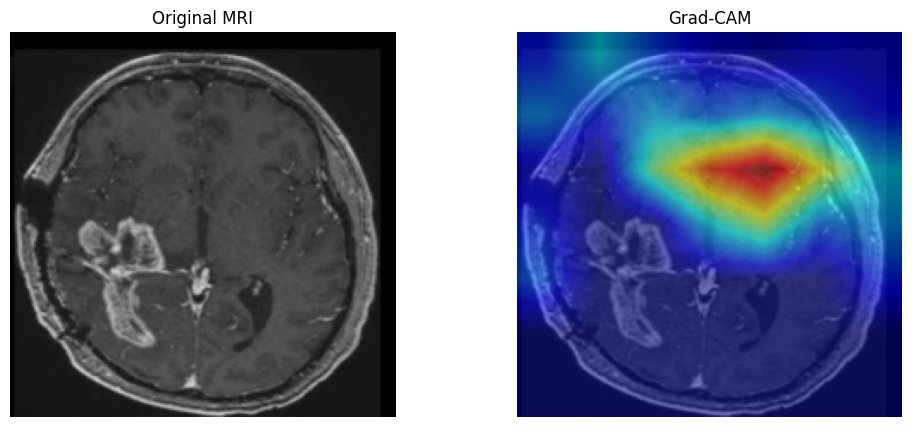

In [ ]:
import matplotlib.pyplot as plt

rgb_img = wrong_image.permute(1,2,0).cpu().numpy()

mean = np.array([0.485,0.456,0.406])
std  = np.array([0.229,0.224,0.225])

rgb_img = std * rgb_img + mean
rgb_img = np.clip(rgb_img,0,1)

visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(rgb_img)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(visualization)
plt.title("Grad-CAM")
plt.axis("off")

plt.show()

In [ ]:
import os

GRADCAM_DIR = f"{PROJECT_DIR}/gradcam"

folders = [
    "glioma_correct",
    "glioma_wrong",
    "meningioma_correct",
    "pituitary_correct"
]

for folder in folders:
    os.makedirs(os.path.join(GRADCAM_DIR, folder), exist_ok=True)

print("Folders Ready!")

Folders Ready!


In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

import matplotlib.pyplot as plt
import numpy as np
import os

cam = GradCAM(
    model=model,
    target_layers=[model.features[8]]
)

targets_needed = {
    "glioma_correct":10,
    "glioma_wrong":10,
    "meningioma_correct":10,
    "pituitary_correct":10
}

saved = {
    "glioma_correct":0,
    "glioma_wrong":0,
    "meningioma_correct":0,
    "pituitary_correct":0
}

classes = test_dataset.classes

model.eval()

for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        preds = torch.argmax(outputs, dim=1)

        probs = torch.softmax(outputs.detach(), dim=1)

        for i in range(len(images)):

            true_name = classes[labels[i]]

            pred_name = classes[preds[i]]

            category = None

            if true_name=="glioma" and pred_name=="glioma":
                category="glioma_correct"

            elif true_name=="glioma" and pred_name!="glioma":
                category="glioma_wrong"

            elif true_name=="meningioma" and pred_name=="meningioma":
                category="meningioma_correct"

            elif true_name=="pituitary" and pred_name=="pituitary":
                category="pituitary_correct"

            if category is None:
                continue

            if saved[category] >= targets_needed[category]:
                continue

            img = images[i].unsqueeze(0)

            grayscale_cam = cam(
                input_tensor=img,
                targets=[ClassifierOutputTarget(preds[i].item())]
            )[0]

            rgb = images[i].permute(1,2,0).cpu().numpy()

            mean=np.array([0.485,0.456,0.406])
            std=np.array([0.229,0.224,0.225])

            rgb=std*rgb+mean
            rgb=np.clip(rgb,0,1)

            overlay = show_cam_on_image(
                rgb,
                grayscale_cam,
                use_rgb=True
            )

            fig,ax=plt.subplots(1,3,figsize=(12,4))

            ax[0].imshow(rgb)
            ax[0].set_title("Original")

            ax[1].imshow(grayscale_cam,cmap="jet")
            ax[1].set_title("Heatmap")

            ax[2].imshow(overlay)
            ax[2].set_title(
                f"T:{true_name}\nP:{pred_name}\n{probs[i].max().item()*100:.1f}%"
            )

            for a in ax:
                a.axis("off")

            save_path=os.path.join(
                GRADCAM_DIR,
                category,
                f"{category}_{saved[category]+1:02d}.png"
            )

            plt.savefig(save_path,bbox_inches="tight")
            plt.close()

            saved[category]+=1

        if all(saved[k]>=targets_needed[k] for k in targets_needed):
            break

print(saved)
print("Done!")

{'glioma_correct': 10, 'glioma_wrong': 10, 'meningioma_correct': 10, 'pituitary_correct': 10}
Done!


**Section 10
Save Model**